# Model: Classification of customers who switch phone companies (churn)
**Authors:** Deivid Matute / Marlon Vargas / Cristian Corella  | **Dataset:** [Telco Customer Churn, IBM (GitHub)](https://github.com/IBM/telco-customer-churn-on-icp4d) | **Type:** binary classification

This notebook follows the project template and leaves the model ready for the API (`models/churn.joblib` + `predictors/churn.py`).

Voice command: *"JarvisTEC, will a customer with 2 months on a month to month fiber optic plan churn?"*

## 1. Problem analysis (0.5 pt)

A telephone company wants to know **which customers are about to leave for the competition**, to call them and offer something before they cancel. The answer is one of two categories ("churn" or "stay"), so it is a supervised **binary classification** problem.

The data is from a fictional company published by IBM (*Telco Customer Churn*): one customer per row, with the services they have contracted, their contract and whether they left during the last month.

Only one in four customers churns, so **accuracy is misleading**: always answering "stay" is right 73.5% of the time without detecting anyone. That is the baseline. The model is considered useful if it beats it on what matters here, which is **finding those who leave**; it is measured with recall (of those who churn, how many it detects), precision (of those it flags, how many really churn) and AUC (how well it ranks customers by risk).

**Support.** Customer churn in telecommunications is a very well studied problem. Verbeke et al. (2012) compared numerous classifiers on eleven real datasets of the sector and found that few variables are enough to predict well and that many classifiers perform similarly; this notebook reaches the same two observations. The treatment of class imbalance and the choice of metrics other than accuracy follow He and Garcia (2009).

In [1]:
# Libraries
import json, warnings
from datetime import date
from pathlib import Path
warnings.filterwarnings('ignore')

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix)

SEED = 42
BLUE, ORANGE, GRAY = '#2563eb', '#ea580c', '#94a3b8'
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 10, 'font.size': 9, 'legend.frameon': False})

## 2. Data understanding (0.5 pt)


In [2]:
# Load: the copy in data/ or, if it is missing (e.g. in Colab), the IBM repository from the assignment
URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
LOCAL = Path('../data/Telco-Customer-Churn.csv')
customers = pd.read_csv(LOCAL if LOCAL.exists() else URL)

print('Rows:', customers.shape[0], '| columns:', customers.shape[1])
print('Nulls:', customers.isna().sum().sum(), '| duplicates:', customers.duplicated().sum(),
      '| distinct customers:', customers.customerID.nunique())
customers.head()

Rows: 7043 | columns: 21
Nulls: 0 | duplicates: 0 | distinct customers: 7043


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# Type of each column, values of the categorical variables and summary of the numeric ones
numeric = customers.select_dtypes('number').columns.tolist()
print('Numeric:', numeric, '| text:', customers.shape[1] - len(numeric), 'columns\n')
for col in customers.columns.drop(['customerID', 'TotalCharges']):
    if customers[col].nunique() <= 4:
        print(f'{col:<17}', customers[col].value_counts().to_dict())
customers.describe().round(2)

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges'] | text: 18 columns

gender            {'Male': 3555, 'Female': 3488}
SeniorCitizen     {0: 5901, 1: 1142}
Partner           {'No': 3641, 'Yes': 3402}
Dependents        {'No': 4933, 'Yes': 2110}
PhoneService      {'Yes': 6361, 'No': 682}
MultipleLines     {'No': 3390, 'Yes': 2971, 'No phone service': 682}
InternetService   {'Fiber optic': 3096, 'DSL': 2421, 'No': 1526}
OnlineSecurity    {'No': 3498, 'Yes': 2019, 'No internet service': 1526}
OnlineBackup      {'No': 3088, 'Yes': 2429, 'No internet service': 1526}
DeviceProtection  {'No': 3095, 'Yes': 2422, 'No internet service': 1526}
TechSupport       {'No': 3473, 'Yes': 2044, 'No internet service': 1526}
StreamingTV       {'No': 2810, 'Yes': 2707, 'No internet service': 1526}
StreamingMovies   {'No': 2785, 'Yes': 2732, 'No internet service': 1526}
Contract          {'Month-to-month': 3875, 'Two year': 1695, 'One year': 1473}
PaperlessBilling  {'Yes': 4171, 'No': 2872}
PaymentMethod

,SeniorCitizen,tenure,MonthlyCharges
count,7043.00,7043.00,7043.00
mean,0.16,32.37,64.76
std,0.37,24.56,30.09
min,0.00,0.00,18.25
25%,0.00,9.00,35.50
50%,0.00,29.00,70.35
75%,0.00,55.00,89.85
max,1.00,72.00,118.75


In [4]:
# TotalCharges should be a number, but it comes as text: some rows have it empty
total = pd.to_numeric(customers.TotalCharges, errors='coerce')
print('Empty TotalCharges:', total.isna().sum(),
      '| months with the company of those customers:', customers.loc[total.isna(), 'tenure'].unique())
print('Correlation of TotalCharges with tenure × MonthlyCharges:',
      round(total.corr(customers.tenure * customers.MonthlyCharges), 4))

Empty TotalCharges: 11 | months with the company of those customers: [0]
Correlation of TotalCharges with tenure × MonthlyCharges: 0.9996


There are **7,043 customers and 21 columns**, with no duplicated rows and, at first sight, no nulls. Only 3 columns come as numbers; the other 18 are text.

| Column | Type | Meaning |
|---|---|---|
| `Churn` | categorical | **Target:** whether the customer left in the last month (Yes / No) |
| `tenure` | numeric | Months with the company (0–72) |
| `MonthlyCharges`, `TotalCharges` | numeric | Monthly charge and total paid since joining (USD) |
| `Contract` | categorical | Contract type: month to month, one year or two years |
| `InternetService` | categorical | Internet through DSL, fiber optic or no internet |
| `PhoneService`, `MultipleLines` | categorical | Has a phone line; has more than one |
| `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` | categorical | Additional services on top of the internet |
| `PaperlessBilling`, `PaymentMethod` | categorical | Paperless billing and payment method |
| `gender`, `SeniorCitizen`, `Partner`, `Dependents` | categorical | Sex, senior citizen (0 / 1), has a partner, has dependents |
| `customerID` | text | Identifier: a different value per customer |

Three cleaning decisions:

* `customerID` is dropped: it is an identifier and does not describe the customer.
* `TotalCharges` is dropped. It comes as text because 11 customers have it empty (all with 0 months: they have not paid anything yet), and it is also almost exactly `tenure × MonthlyCharges` (correlation 0.9996), so it adds no information.
* In the additional services, "No internet service" and "No phone service" become "No". The fact that the customer has no internet is already said by `InternetService`; repeating it in six columns only duplicates information.

The target is renamed to `churn` / `stay` because that label is the one the assistant says out loud.

In [5]:
# Cleaning
customers = customers.drop(columns=['customerID', 'TotalCharges'])
customers = customers.replace({'No internet service': 'No', 'No phone service': 'No'})
customers['Churn'] = customers['Churn'].map({'Yes': 'churn', 'No': 'stay'})
POSITIVE = 'churn'      # the class we want to detect

print(customers.Churn.value_counts().to_dict(), '|', round((customers.Churn == POSITIVE).mean() * 100, 1), '% churn')

{'stay': 5174, 'churn': 1869} | 26.5 % churn


## 3. Data exploration (0.5 pt)


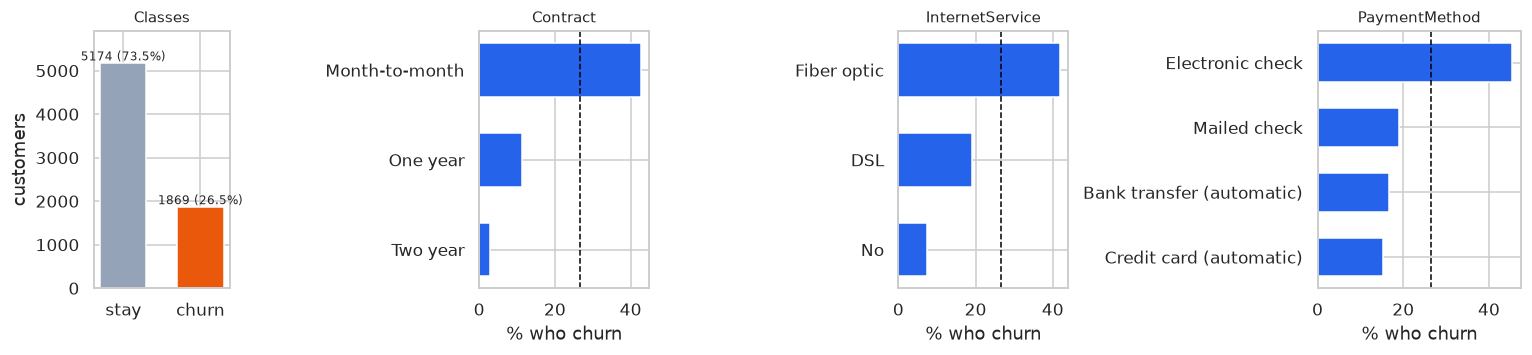

Contract {'Two year': 2.8, 'One year': 11.3, 'Month-to-month': 42.7}
InternetService {'No': 7.4, 'DSL': 19.0, 'Fiber optic': 41.9}
PaymentMethod {'Credit card (automatic)': 15.2, 'Bank transfer (automatic)': 16.7, 'Mailed check': 19.1, 'Electronic check': 45.3}


In [6]:
# How many churn, and how that percentage changes by contract, internet service and payment method
def rate(col):
    """Percentage of customers who churn in each category of a column."""
    return (customers.groupby(col).Churn.apply(lambda s: (s == POSITIVE).mean()) * 100).sort_values()

OVERALL = (customers.Churn == POSITIVE).mean() * 100

fig, ax = plt.subplots(1, 4, figsize=(14, 3.3), gridspec_kw={'width_ratios': [0.8, 1, 1, 1.2]})
counts = customers.Churn.value_counts()
ax[0].bar(counts.index, counts.values, color=[GRAY, ORANGE], width=0.6)
for i, v in enumerate(counts.values):
    ax[0].text(i, v + 60, f'{v} ({v / len(customers):.1%})', ha='center', fontsize=8)
ax[0].set_ylabel('customers'); ax[0].set_title('Classes'); ax[0].set_ylim(0, 5900)
for a, col in zip(ax[1:], ['Contract', 'InternetService', 'PaymentMethod']):
    t = rate(col)
    a.barh(t.index, t.values, color=BLUE, height=0.6)
    a.axvline(OVERALL, color='black', lw=1, ls='--')
    a.set_xlabel('% who churn'); a.set_title(col)
plt.tight_layout(); plt.show()

for col in ['Contract', 'InternetService', 'PaymentMethod']:
    print(col, rate(col).round(1).to_dict())

**The classes are imbalanced:** 1,869 customers churn (26.5%) and 5,174 stay. That is why the split will be stratified and accuracy will not be the main metric.

The contract is what separates the most: 42.7% of those who pay month to month leave, versus 11.3% with a one-year contract and 2.8% with the two-year one. Fiber-optic customers also leave much more (41.9%, versus 19.0% on DSL), as do those who pay with an electronic check (45.3%, versus 15 to 19% with the other payment methods). The dashed line is the overall average.

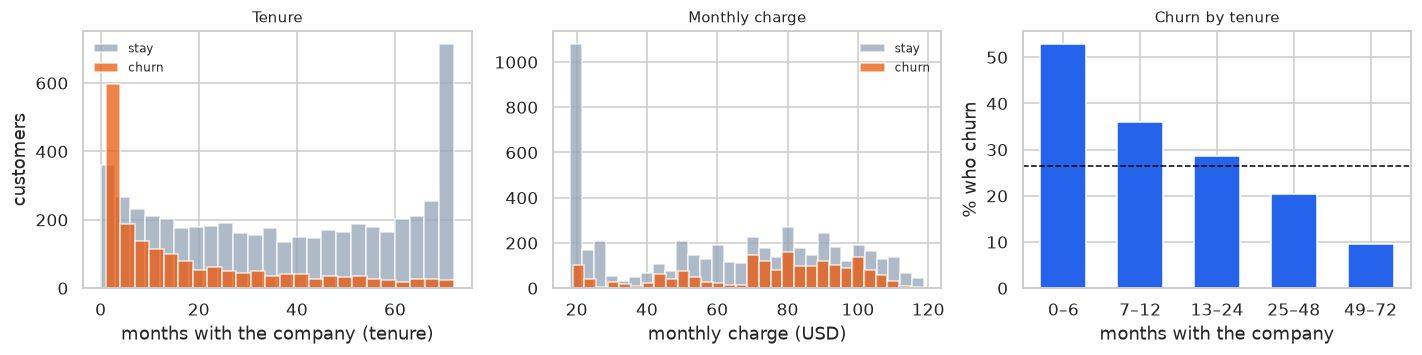

% who churn by tenure band: {'0–6': 52.9, '7–12': 35.9, '13–24': 28.7, '25–48': 20.4, '49–72': 9.5}
Medians   {'tenure': {'churn': 10.0, 'stay': 38.0}, 'MonthlyCharges': {'churn': 79.65, 'stay': 64.42500000000001}}


In [7]:
# Tenure and monthly charge of those who stay and those who churn
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
for cls, color in [('stay', GRAY), ('churn', ORANGE)]:
    group = customers[customers.Churn == cls]
    ax[0].hist(group.tenure, bins=24, alpha=0.75, color=color, label=cls)
    ax[1].hist(group.MonthlyCharges, bins=30, alpha=0.75, color=color, label=cls)
ax[0].set_xlabel('months with the company (tenure)'); ax[0].set_ylabel('customers'); ax[0].set_title('Tenure'); ax[0].legend(fontsize=8)
ax[1].set_xlabel('monthly charge (USD)'); ax[1].set_title('Monthly charge'); ax[1].legend(fontsize=8)

bands = pd.cut(customers.tenure, [-1, 6, 12, 24, 48, 72], labels=['0–6', '7–12', '13–24', '25–48', '49–72'])
by_band = customers.groupby(bands, observed=True).Churn.apply(lambda s: (s == POSITIVE).mean()) * 100
ax[2].bar(by_band.index.astype(str), by_band.values, color=BLUE, width=0.6)
ax[2].axhline(OVERALL, color='black', lw=1, ls='--')
ax[2].set_xlabel('months with the company'); ax[2].set_ylabel('% who churn'); ax[2].set_title('Churn by tenure')
plt.tight_layout(); plt.show()

print('% who churn by tenure band:', by_band.round(1).to_dict())
print('Medians  ', customers.groupby('Churn')[['tenure', 'MonthlyCharges']].median().to_dict())

Churn is concentrated in the first months: 52.9% of the customers with 6 months or less leave and only 9.5% of those with more than 4 years. Half of those who churn had been with the company for 10 months or less; among those who stay, half have 38 or more. Those who leave also pay more per month (median 79.65 USD versus 64.43), and in the group that pays the minimum, about 20 USD, very few leave.

Decision: `tenure` enters the model as it is. Since it is in months and the other variables are 0 and 1, the numeric variables are **standardized** so that logistic regression treats them on the same scale.

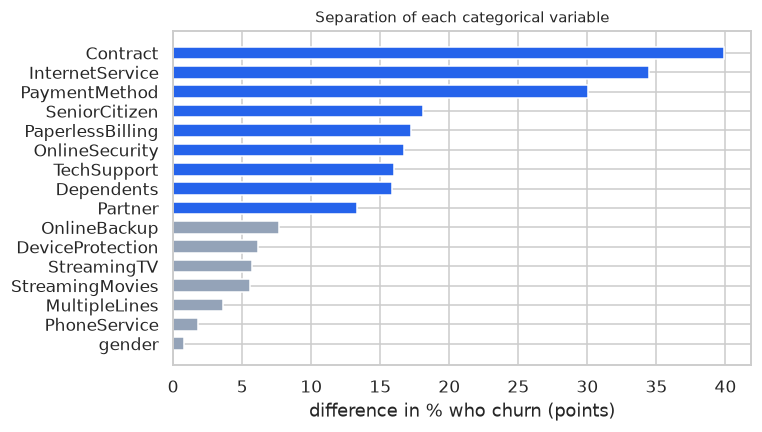

{'Contract': 39.9, 'InternetService': 34.5, 'PaymentMethod': 30.0, 'SeniorCitizen': 18.1, 'PaperlessBilling': 17.2, 'OnlineSecurity': 16.7, 'TechSupport': 16.0, 'Dependents': 15.8, 'Partner': 13.3, 'OnlineBackup': 7.6, 'DeviceProtection': 6.1, 'StreamingTV': 5.7, 'StreamingMovies': 5.6, 'MultipleLines': 3.6, 'PhoneService': 1.8, 'gender': 0.8}


In [8]:
# How much each categorical variable separates: points between its highest-churn category and its lowest-churn one
categorical = [c for c in customers.columns if c not in ['tenure', 'MonthlyCharges', 'Churn']]
separation = pd.Series({c: rate(c).max() - rate(c).min() for c in categorical}).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(separation.index, separation.values, color=[BLUE if v >= 10 else GRAY for v in separation.values], height=0.65)
ax.set_xlabel('difference in % who churn (points)'); ax.set_title('Separation of each categorical variable')
plt.tight_layout(); plt.show()

print(separation.round(1).sort_values(ascending=False).to_dict())

Looking at each variable separately, the ones that separate the most are the contract (39.9 points between its best and its worst category), the internet service (34.5) and the payment method (30.0). At the other extreme, sex (0.8) and having a phone line (1.8) hardly change anything.

This chart looks at one variable at a time and does not say which ones repeat each other. That is checked in the model section, by measuring how much each one adds when the others are already there.

## 4. Model (2 pts)

**Preparation:** the categorical variables are converted to 0/1 columns (*one-hot*) and the numeric ones are standardized. The split is 80% training and 20% test, **stratified** so that both parts have the same 26.5% of customers who churn.

Five alternatives are compared, all inside a `Pipeline` so that the preparation is fitted only with the training data:

1. Baseline: always answer "stay".
2. Logistic regression (Hosmer et al., 2013).
3. **Balanced** logistic regression (`class_weight='balanced'`): a mistake on a customer who churns weighs more, in proportion to how scarce they are.
4. Decision tree of depth 5, balanced.
5. Random Forest of 300 trees (Breiman, 2001), balanced.

The models are compared with **5-fold cross-validation on the training set**. The test set is not touched until the final evaluation.

In [9]:
X = customers.drop(columns='Churn')
y = customers['Churn']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print('Training:', len(X_tr), '| test:', len(X_te), '| churn in each part:',
      f'{(y_tr == POSITIVE).mean():.1%} and {(y_te == POSITIVE).mean():.1%}')

NUMERICAL = ['SeniorCitizen', 'tenure', 'MonthlyCharges']
ALL_COLUMNS = list(X.columns)

def build(model, columns):
    """Pipeline: preparation + model, using only the given columns."""
    prepare = ColumnTransformer([
        ('categorical', OneHotEncoder(drop='if_binary', handle_unknown='ignore'),
         [c for c in columns if c not in NUMERICAL]),
        ('numeric', StandardScaler(), [c for c in columns if c in NUMERICAL])])
    return Pipeline([('prepare', prepare), ('model', model)])

def compute_metrics(actual, prob):
    """Metrics from the probability of 'churn' (the customer is flagged from 0.5)."""
    pred = np.where(prob >= 0.5, POSITIVE, 'stay')
    return {'accuracy': accuracy_score(actual, pred),
            'recall': recall_score(actual, pred, pos_label=POSITIVE, zero_division=0),
            'precision': precision_score(actual, pred, pos_label=POSITIVE, zero_division=0),
            'F1': f1_score(actual, pred, pos_label=POSITIVE, zero_division=0),
            'AUC': roc_auc_score(actual == POSITIVE, prob)}

folds = StratifiedKFold(5, shuffle=True, random_state=SEED)

def validate(model, columns):
    """5-fold cross-validation using only the training data."""
    prob = cross_val_predict(build(model, columns), X_tr[columns], y_tr, cv=folds,
                             method='predict_proba')[:, 0]      # column 0 = 'churn' (alphabetical order)
    return compute_metrics(y_tr, prob)

def logistic():
    return LogisticRegression(max_iter=1000, class_weight='balanced')

candidates = {
    'Baseline (always "stay")':               DummyClassifier(strategy='most_frequent'),
    'Logistic regression':                    LogisticRegression(max_iter=1000),
    'Balanced logistic regression':           logistic(),
    'Decision tree (depth 5, balanced)':      DecisionTreeClassifier(max_depth=5, class_weight='balanced',
                                                                     random_state=SEED),
    'Random Forest (300, balanced)':          RandomForestClassifier(300, min_samples_leaf=10, class_weight='balanced',
                                                                     random_state=SEED, n_jobs=-1)}
table = pd.DataFrame({name: validate(model, ALL_COLUMNS) for name, model in candidates.items()}).T.round(3)
table

Training: 5634 | test: 1409 | churn in each part: 26.5% and 26.5%


,accuracy,recall,precision,F1,AUC
"Baseline (always ""stay"")",0.735,0.000,0.000,0.000,0.500
Logistic regression,0.806,0.548,0.662,0.599,0.846
Balanced logistic regression,0.751,0.787,0.521,0.627,0.846
"Decision tree (depth 5, balanced)",0.736,0.817,0.501,0.621,0.833
"Random Forest (300, balanced)",0.769,0.769,0.545,0.638,0.848


Logistic regression without balancing has the best accuracy (0.806), but it only detects 55% of those who churn. When the classes are balanced the accuracy drops to 0.751 and the recall rises to 0.787: it detects almost 4 out of 5. The AUC does not change (0.846 in both) because they rank the customers practically the same way; what changes is the point from which they flag them.

Among the three balanced models, the Random Forest is just slightly ahead (AUC 0.848 versus 0.846; F1 0.636 versus 0.627) and the tree is behind (0.833). **Balanced logistic regression** is chosen: the difference with the forest is 0.002 in AUC and, in exchange, the model is simpler, its coefficients say what pushes each prediction and the exported file weighs less than 10 KB.

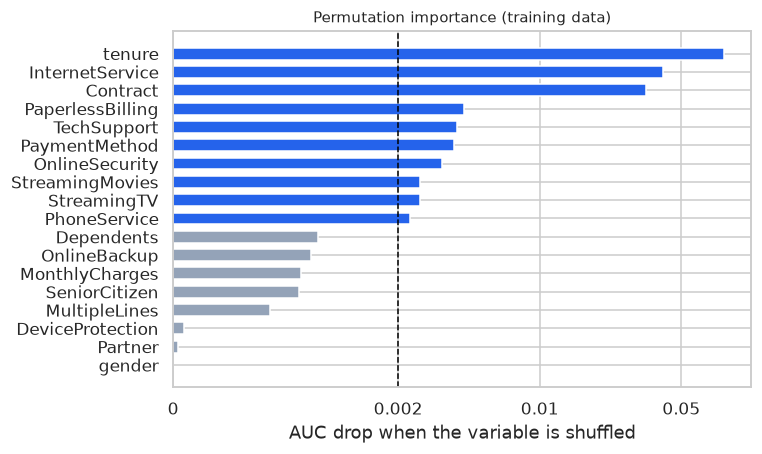

Variables above the cutoff: 10 | they are the selected ones: True
{'tenure': 0.081, 'InternetService': 0.0406, 'Contract': 0.0334, 'PaperlessBilling': 0.0042, 'TechSupport': 0.0039, 'PaymentMethod': 0.0038, 'OnlineSecurity': 0.0033, 'StreamingMovies': 0.0026, 'StreamingTV': 0.0026, 'PhoneService': 0.0023, 'Dependents': 0.0013, 'OnlineBackup': 0.0012, 'MonthlyCharges': 0.0011, 'SeniorCitizen': 0.0011, 'MultipleLines': 0.0009, 'DeviceProtection': 0.0001, 'Partner': 0.0, 'gender': 0.0}
R² of the monthly charge explained only by the contracted services: 0.9988


,accuracy,recall,precision,F1,AUC
With all 18 variables,0.751,0.787,0.521,0.627,0.846
With the 10 selected,0.752,0.795,0.521,0.630,0.845


In [10]:
# Are all 18 variables needed? Permutation importance: one column is shuffled and the AUC drop is measured
full_model = build(logistic(), ALL_COLUMNS).fit(X_tr, y_tr)
importance = pd.Series(permutation_importance(full_model, X_tr, y_tr, scoring='roc_auc', n_repeats=20,
                                              random_state=SEED).importances_mean, index=ALL_COLUMNS).sort_values()
CUTOFF = 0.002

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(importance.index, importance.values, color=[BLUE if v >= CUTOFF else GRAY for v in importance.values], height=0.65)
ax.set_xscale('symlog', linthresh=0.002); ax.set_xticks([0, 0.002, 0.01, 0.05]); ax.set_xticklabels(['0', '0.002', '0.01', '0.05'])
ax.axvline(CUTOFF, color='black', lw=1, ls='--')
ax.set_xlabel('AUC drop when the variable is shuffled'); ax.set_title('Permutation importance (training data)')
plt.tight_layout(); plt.show()

SELECTED = ['tenure', 'InternetService', 'Contract', 'PaperlessBilling', 'TechSupport', 'PaymentMethod',
            'OnlineSecurity', 'StreamingMovies', 'StreamingTV', 'PhoneService']
print('Variables above the cutoff:', int((importance >= CUTOFF).sum()),
      '| they are the selected ones:', sorted(importance[importance >= CUTOFF].index) == sorted(SELECTED))
print(importance.sort_values(ascending=False).round(4).to_dict())

services = pd.get_dummies(X_tr.drop(columns=['MonthlyCharges', 'tenure', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
                                             'Contract', 'PaperlessBilling', 'PaymentMethod']))
print('R² of the monthly charge explained only by the contracted services:',
      round(LinearRegression().fit(services, X_tr.MonthlyCharges).score(services, X_tr.MonthlyCharges), 4))

comparison = pd.DataFrame({'With all 18 variables': validate(logistic(), ALL_COLUMNS),
                           'With the 10 selected':  validate(logistic(), SELECTED)}).T.round(3)
comparison

In [11]:
# Why a variable that separates on its own may add nothing: the case of senior citizens (training data)
train_df = X_tr.assign(churns=(y_tr == POSITIVE))
seniors = train_df.SeniorCitizen == 1
profile = (train_df.Contract == 'Month-to-month') & (train_df.InternetService == 'Fiber optic')
print(f'Churn                                 seniors {train_df[seniors].churns.mean():.1%} | rest {train_df[~seniors].churns.mean():.1%}')
print(f'Have fiber and a monthly contract     seniors {profile[seniors].mean():.1%} | rest {profile[~seniors].mean():.1%}')
print(f'Churn, within that profile            seniors {train_df[seniors & profile].churns.mean():.1%} | rest {train_df[~seniors & profile].churns.mean():.1%}')

Churn                                 seniors 42.5% | rest 23.4%
Have fiber and a monthly contract     seniors 56.4% | rest 25.0%
Churn, within that profile            seniors 58.4% | rest 53.0%


Permutation importance (Breiman, 2001) measures how much the AUC drops when a column is shuffled, that is, how much that variable adds **when the model already has the others**. It is computed only with the training data.

Three variables do almost all the work: tenure (0.081), internet service (0.041) and contract (0.033). Seven others add between 0.002 and 0.004. The remaining eight are below 0.002 and are discarded.

**With 10 variables the model performs the same as with the 18** (AUC 0.845 versus 0.846; recall 0.795 versus 0.787). The one with 10 is chosen: the instructions are given by voice and each piece of data the user does not say is filled in with the typical value, so it is convenient to ask for few.

Two discards that stand out:

* **`MonthlyCharges`.** Those who leave pay more, but the monthly charge is a consequence of the contracted services: with only the services it is reconstructed almost exactly (R² of 0.999), and the main ones are already in the model.
* **`SeniorCitizen`.** Senior citizens churn more (42.5% versus 23.4%), but they also have fiber and a monthly contract much more often (56.4% versus 25.0%). Comparing customers with that same profile, the difference shrinks to 58.4% versus 53.0%: almost everything age said is already said by the internet service and the contract.

## 5. Evaluation (1 pt)


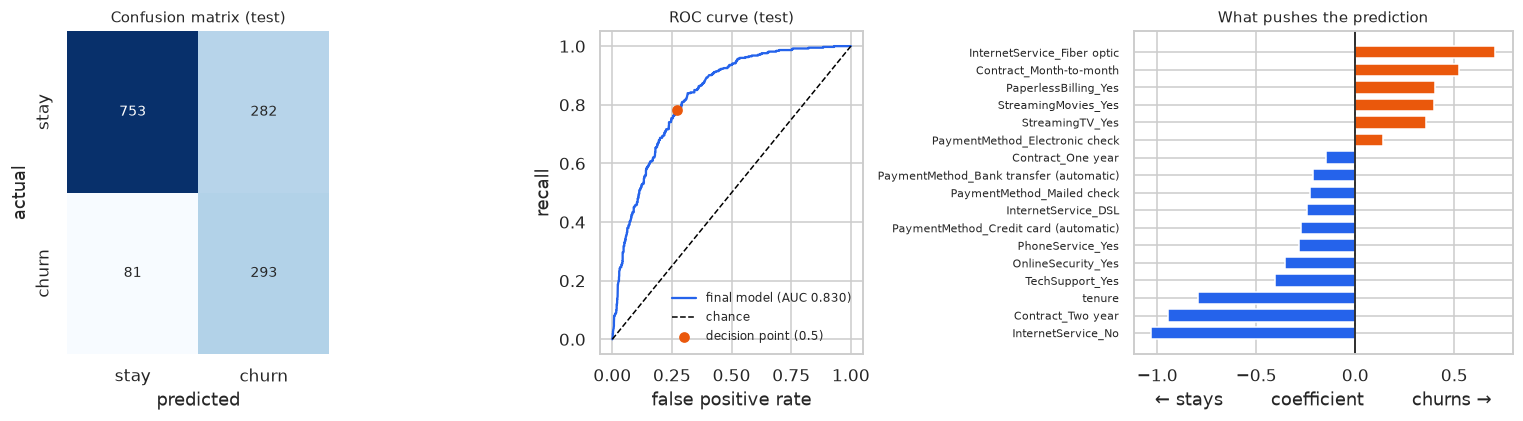

TN=753  FP=282  FN=81  TP=293
{'InternetService_Fiber optic': 0.71, 'Contract_Month-to-month': 0.52, 'PaperlessBilling_Yes': 0.4, 'StreamingMovies_Yes': 0.4, 'StreamingTV_Yes': 0.36, 'PaymentMethod_Electronic check': 0.14, 'Contract_One year': -0.15, 'PaymentMethod_Bank transfer (automatic)': -0.21, 'PaymentMethod_Mailed check': -0.23, 'InternetService_DSL': -0.25, 'PaymentMethod_Credit card (automatic)': -0.27, 'PhoneService_Yes': -0.28, 'OnlineSecurity_Yes': -0.35, 'TechSupport_Yes': -0.41, 'tenure': -0.79, 'Contract_Two year': -0.94, 'InternetService_No': -1.03}


,accuracy,recall,precision,F1,AUC
Cross-validation,0.752,0.795,0.521,0.630,0.845
Test,0.742,0.783,0.510,0.617,0.830
Baseline on test,0.735,0.000,0.000,0.000,0.500


In [12]:
final = build(logistic(), SELECTED).fit(X_tr[SELECTED], y_tr)
prob = final.predict_proba(X_te[SELECTED])[:, 0]
pred = final.predict(X_te[SELECTED])

summary = pd.DataFrame({'Cross-validation': validate(logistic(), SELECTED),
                        'Test': compute_metrics(y_te, prob),
                        'Baseline on test': compute_metrics(y_te, np.zeros(len(y_te)))}).T.round(3)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.9), gridspec_kw={'width_ratios': [0.9, 0.9, 1.3]})
ORDER = ['stay', 'churn']
matrix = confusion_matrix(y_te, pred, labels=ORDER)
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=ORDER, yticklabels=ORDER, ax=ax[0])
ax[0].set_xlabel('predicted'); ax[0].set_ylabel('actual'); ax[0].set_title('Confusion matrix (test)')

fpr, tpr, _ = roc_curve(y_te == POSITIVE, prob)
ax[1].plot(fpr, tpr, color=BLUE, label=f"final model (AUC {summary.loc['Test', 'AUC']:.3f})")
ax[1].plot([0, 1], [0, 1], color='black', lw=1, ls='--', label='chance')
ax[1].scatter(matrix[0, 1] / matrix[0].sum(), matrix[1, 1] / matrix[1].sum(), color=ORANGE, zorder=3, label='decision point (0.5)')
ax[1].set_xlabel('false positive rate'); ax[1].set_ylabel('recall'); ax[1].set_title('ROC curve (test)'); ax[1].legend(fontsize=8)

# Coefficients: positive = pushes towards "churn". The sign is flipped because sklearn gives them for the 'stay' class
names = [n.split('__')[1] for n in final.named_steps['prepare'].get_feature_names_out()]
coef = pd.Series(-final.named_steps['model'].coef_[0], index=names).sort_values()
ax[2].barh(coef.index, coef.values, color=[ORANGE if v > 0 else BLUE for v in coef.values], height=0.7)
ax[2].axvline(0, color='black', lw=1); ax[2].tick_params(axis='y', labelsize=7)
ax[2].set_xlabel('← stays        coefficient        churns →'); ax[2].set_title('What pushes the prediction')
plt.tight_layout(); plt.show()

tn, fp, fn, tp = matrix.ravel()
print(f'TN={tn}  FP={fp}  FN={fn}  TP={tp}')
print(coef.round(2).sort_values(ascending=False).to_dict())
summary

In [13]:
# Whom does it miss? Test customers who churned: those the model flagged versus those that slipped away
leavers = X_te[SELECTED].assign(pred=pred)[y_te == POSITIVE]
detected, missed = leavers[leavers.pred == POSITIVE], leavers[leavers.pred == 'stay']
rows = {}
for name, g in [('detected', detected), ('missed', missed)]:
    rows[name] = {'customers': len(g), 'months (median)': g.tenure.median(),
                  '% monthly contract': round((g.Contract == 'Month-to-month').mean() * 100, 1),
                  '% fiber optic': round((g.InternetService == 'Fiber optic').mean() * 100, 1)}
pd.DataFrame(rows).T

,customers,months (median),% monthly contract,% fiber optic
detected,293.0,9.0,97.6,77.8
missed,81.0,37.0,61.7,33.3


On the test set (1,409 customers the model never saw) the results are a bit lower than in cross-validation, but similar: recall of 0.783 versus 0.795 and AUC of 0.830 versus 0.845. There is no sign of overfitting.

**Reading the confusion matrix.** Of the 374 customers who churned, the model detected **293 (78%)** and 81 slipped away. In exchange, it flagged 282 who actually stayed: out of every two customers it flags, one was really leaving (precision of 0.51). The accuracy (0.742) is just above the baseline (0.735), and still the model is much more useful: the baseline detects none.

For a retention campaign this balance is convenient: calling a customer who was not planning to leave costs little, and losing one who was leaving costs the payments of the following months.

**What pushes the prediction.** Towards "churn": fiber optic, the month-to-month contract, paperless billing and having movies or TV over the internet. Towards "stay": having no internet, the two-year contract, tenure and having tech support or online security.

**Where it is wrong.** The 81 that slip away do not look like the customer who usually leaves: they have been with the company for 37 months (the detected ones, 9), only 62% have a monthly contract (the detected ones, 98%) and only a third have fiber (the detected ones, 78%). They are long-standing customers with a stable profile who left anyway, for reasons this data does not capture.

## 6. Conclusion (0.5 pt)

* With a **balanced logistic regression** of 10 variables, **78% of the customers who switch** companies are detected (AUC of 0.83 on test); the baseline detects none.
* The cost is the false alarms: half of the customers the model flags did not churn.
* What weighs the most is **tenure**, the **type of internet** and the **contract**: the highest-risk customer is new, with fiber optic and a month-to-month contract.
* Balancing the classes was the key decision: without it the same model detects only 55%.
* Eight variables were discarded without losing performance, which leaves a model that can be used by dictating little data.
* Limitations: the data is from a fictional company and from a single moment, so the percentages cannot be transferred to a real operator. In addition, the model does not see the cause of churn (competitor offers, complaints, service quality), which is why long-standing customers slip away.

## Export the model
The chosen model is **retrained with all the data** and saved together with the typical value of each variable, so the API can fill in what the user does not say.

In [14]:
final.fit(X[SELECTED], y)

bundle = {
    'pipeline': final, 'model': 'Balanced logistic regression', 'features': SELECTED,
    'classes': list(map(str, final.classes_)), 'positive': POSITIVE,
    'typical_values': {c: (int(X[c].median()) if c in NUMERICAL else str(X[c].mode()[0])) for c in SELECTED},
    'categories': {c: sorted(map(str, X[c].unique())) for c in SELECTED if c not in NUMERICAL},
    'sklearn': sklearn.__version__,
    'cv_metrics': summary.loc['Cross-validation'].to_dict(), 'test_metrics': summary.loc['Test'].to_dict(),
}
joblib.dump(bundle, '../models/churn.joblib', compress=3)
print('Saved ../models/churn.joblib | scikit-learn', sklearn.__version__)

# API contract check
import sys; sys.path.insert(0, '..')          # to import predictors/
from predictors.churn import predict
new_customer = {'tenure': 2, 'InternetService': 'Fiber optic', 'Contract': 'Month-to-month'}
loyal = {'tenure': 60, 'InternetService': 'DSL', 'Contract': 'Two year', 'TechSupport': 'Yes',
         'OnlineSecurity': 'Yes', 'PaymentMethod': 'Credit card (automatic)'}
for customer in (new_customer, loyal):
    r = predict(customer)
    print(customer, '->', r['label'], '| risk score', r['risk_score'])

Saved ../models/churn.joblib | scikit-learn 1.8.0
{'tenure': 2, 'InternetService': 'Fiber optic', 'Contract': 'Month-to-month'} -> churn | risk score 0.87
{'tenure': 60, 'InternetService': 'DSL', 'Contract': 'Two year', 'TechSupport': 'Yes', 'OnlineSecurity': 'Yes', 'PaymentMethod': 'Credit card (automatic)'} -> stay | risk score 0.03
